# KV260 NMPC Platform Audit and Hardware-in-the-Loop Test



This notebook audits the Vivado/HLS contract, validates deployment artifacts, and runs the Sniffbot quadrotor NMPC loop on Kria PYNQ. The PL returns a best **control sequence**; Python applies its first control to predict the next state.



## 1. Configure Repository and Deployment Paths



The first executable cell locates the project inputs and records the host, Python, Vivado-script, and board metadata. Missing repository-only paths are tolerated after this directory has been copied to the KV260.

In [1]:
# Run this cell if pandas is not installed on the Kria-PYNQ environment
#%pip install pandas

In [2]:
from __future__ import annotations

import csv
import json
from pathlib import Path
import platform
import re
import subprocess
import sys
import time
import xml.etree.ElementTree as ET
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "nmpc_overlay.py").is_file():
    matches = list(notebook_dir.rglob("app/kria-pynq/nmpc_overlay.py"))
    if matches:
        notebook_dir = matches[0].parent
sys.path.insert(0, str(notebook_dir))

from nmpc_overlay import DESIGN_REVISION, NmpcOverlay
from quadrotor import quadrotor_step, reference_horizon, spiral_reference, tracking_metrics
from package_overlay import pso_fsm_register_map

repo_root = notebook_dir.parents[1] if notebook_dir.name == "kria-pynq" else notebook_dir
paths = {
    "address_csv": repo_root / "hw/exported_platform/nmpc_solver_v2_debug/AddressSegments.csv",
    "vivado_tcl": repo_root / "hw/hdl/nmpc_solver_v2_debug.tcl",
    "ip_repo": repo_root / "hw/hls/vitis_ip_repo",
    "config_hpp": repo_root / "hw/hls/source/include/config.hpp",
    "matlab_model": repo_root / "app/matlab_ws/QuadrotorSystem.m",
    "xsa": repo_root / "hw/exported_platform/nmpc_solver_v2.xsa",
    "xsa_files": repo_root / "hw/exported_platform/",
    # The deployed overlay is the authoritative hardware description on the board.
    "handoff_hwh": repo_root / "app/kria-pynq/overlay/design_nmpc_solver.hwh",
    "handoff_bda": repo_root / "app/kria-pynq/overlay/design_nmpc_solver.bda",
    "bitstream": repo_root / "hw/exported_platform/nmpc_solver_v2_debug/nmpc_solver_v2.bit",
    "overlay": repo_root / "app/kria-pynq/overlay",
    "logs": repo_root / "app/kria-pynq/validation_logs",
}
path_status = pd.DataFrame(
    [{"name": name, "path": str(path), "exists": path.exists()} for name, path in paths.items()]
)
display(path_status)
print({
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "design_revision": DESIGN_REVISION,
    "pynq": "available" if __import__("importlib").util.find_spec("pynq") else "not installed",
})

,name,path,exists
0,address_csv,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,True
1,vivado_tcl,/root/jupyter_notebooks/nmpc_hls/hw/hdl/nmpc_s...,False
2,ip_repo,/root/jupyter_notebooks/nmpc_hls/hw/hls/vitis_...,True
3,config_hpp,/root/jupyter_notebooks/nmpc_hls/hw/hls/source...,True
4,matlab_model,/root/jupyter_notebooks/nmpc_hls/app/matlab_ws...,True
5,xsa,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,True
6,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,True
7,handoff_hwh,/root/jupyter_notebooks/nmpc_hls/app/kria-pynq...,True
8,handoff_bda,/root/jupyter_notebooks/nmpc_hls/app/kria-pynq...,True
9,bitstream,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,True


{'python': '3.10.12', 'platform': 'Linux-5.15.0-1080-xilinx-zynqmp-aarch64-with-glibc2.35', 'design_revision': 4, 'pynq': 'available'}


## 2. Parse the Vivado Project-Generation Script



Extract the target, board, block design, custom IPs, SmartConnect sizes, local pointer constants, clock/reset nets, and address assignments.



## 3. Validate KV260 Part, Board, Clock, and Reset Configuration



The expected pair is `xck26-sfvc784-2LV-c` and `xilinx.com:kv260_som:part0:1.4`. PL clock 0 must reach HPM0, HP0, SmartConnect, BRAM controllers, and every HLS core; `proc_sys_reset` must provide synchronized active-low reset.



## 4. Inspect HLS IP Definitions and VLNV Consistency



Compare every Tcl VLNV with packaged `component.xml` metadata. Mixed vendor strings are legal only when they exactly match the packaged component.

In [3]:
tcl_path = paths["vivado_tcl"]

if not tcl_path.is_file():

    print("Repository Tcl is not present on this board copy; static audit skipped.")

    tcl_text = ""

else:

    tcl_text = tcl_path.read_text(encoding="utf-8")
tcl_has_fix_set = all(marker in tcl_text for marker in ("axis_rand_fanout", "updateParticlesWithD_0/iteration"))
if tcl_text and not tcl_has_fix_set:
    print("This repository Tcl predates the deployed fix set (stale snapshot): the static Tcl audit "
          "below is informational only. The deployed overlay HWH is audited in the next cell.")



def first_match(pattern, text):

    match = re.search(pattern, text, re.MULTILINE)

    return match.group(1) if match else None



project_config = {
    "part": first_match(r"create_project[^\n]+-part\s+(\S+)", tcl_text),
    "board_part": first_match(r'set_property -name "board_part" -value "([^"]+)"', tcl_text),
    "block_design": first_match(r"set design_name\s+(\S+)", tcl_text),
    "ip_repo_expression": first_match(r"set ip_repo_dir\s+(.+)", tcl_text),
    "pl_clock_hz": 100_000_000 if "PSU__CRL_APB__PL0_REF_CTRL__FREQMHZ {100}" in tcl_text else None,
    "hls_clock_ns": 10.0,
}

display(pd.DataFrame([project_config]))



vlnvs = sorted(set(re.findall(r"-vlnv\s+([^\s\]]+)", tcl_text)))

custom_vlnvs = [value for value in vlnvs if ":hls:" in value]

smartconnects = re.findall(
    r"set (smartconnect_\d+) .*?\n\s*set_property CONFIG.NUM_SI \{(\d+)\}",
    tcl_text,
    re.DOTALL,
)

constants = re.findall(
    r"set (\w+) \[ create_bd_cell -type inline_hdl -vlnv xilinx\.com:inline_hdl:ilconstant:1\.0 \w+ \]\s*set_property -dict \[list \\\s*CONFIG\.CONST_VAL \{(\d+)\}",
    tcl_text,
    re.DOTALL,
)

display(pd.DataFrame(smartconnects, columns=["smartconnect", "num_slave_inputs"]))

display(pd.DataFrame(constants, columns=["constant", "byte_offset"]))



component_rows = []

for component_path in paths["ip_repo"].glob("*/component.xml") if paths["ip_repo"].is_dir() else []:

    root = ET.parse(component_path).getroot()

    ns = {"spirit": "http://www.spiritconsortium.org/XMLSchema/SPIRIT/1685-2009"}

    fields = {}

    for key in ("vendor", "library", "name", "version"):

        node = root.find(f"spirit:{key}", ns)

        fields[key] = node.text if node is not None else None

    fields["vlnv"] = ":".join(fields[key] or "" for key in ("vendor", "library", "name", "version"))

    fields["used_by_tcl"] = fields["vlnv"] in custom_vlnvs

    component_rows.append(fields)

component_table = pd.DataFrame(component_rows)

display(component_table)



clock_checks = {

    "part_ok": project_config["part"] == "xck26-sfvc784-2LV-c",

    "board_ok": project_config["board_part"] == "xilinx.com:kv260_som:part0:1.4",

    "clock_matches_hls": project_config["pl_clock_hz"] == int(1e9 / project_config["hls_clock_ns"]),

    "hp0_clocked": "saxihp0_fpd_aclk" in tcl_text,

    "hpm0_clocked": "maxihpm0_fpd_aclk" in tcl_text,

    "synchronized_reset": "rst_ps8_0_96M/peripheral_aresetn" in tcl_text,

    "all_custom_vlnvs_packaged": all(

        value in set(component_table.get("vlnv", [])) for value in custom_vlnvs

    ),

}

if not tcl_text:
    clock_checks = dict.fromkeys(clock_checks)  # None = skipped: nothing to audit without the Tcl
display(pd.Series(clock_checks, name="pass", dtype=object))

Repository Tcl is not present on this board copy; static audit skipped.


,part,board_part,block_design,ip_repo_expression,pl_clock_hz,hls_clock_ns
0,None,None,None,None,None,10.0


,smartconnect,num_slave_inputs


,constant,byte_offset


,vendor,library,name,version,vlnv,used_by_tcl
0,tu-dresden_turun-yliopisto,hls,initializeParticles_set,1.0,tu-dresden_turun-yliopisto:hls:initializeParti...,False
1,turun-yliopisto,hls,evaluateFitnessAndDetectLocalBest,1.0,turun-yliopisto:hls:evaluateFitnessAndDetectLo...,False
2,tu-dresden,hls,nonlinear_solver_wrapper,1.0,tu-dresden:hls:nonlinear_solver_wrapper:1.0,False
3,tu-dresden_turun-yliopisto,hls,detectGlobalMinimum,1.0,tu-dresden_turun-yliopisto:hls:detectGlobalMin...,False
4,tu-dresden_turun-yliopisto,hls,updateParticlesWithDuConstrains,1.0,tu-dresden_turun-yliopisto:hls:updateParticles...,False
5,tu-dresden_turun-yliopisto,hls,pso_fsm,1.0,tu-dresden_turun-yliopisto:hls:pso_fsm:1.0,False
6,tu-dresden_turun-yliopisto,hls,rand_wrapper,1.0,tu-dresden_turun-yliopisto:hls:rand_wrapper:1.0,False


part_ok                      None
board_ok                     None
clock_matches_hls            None
hp0_clocked                  None
hpm0_clocked                 None
synchronized_reset           None
all_custom_vlnvs_packaged    None
Name: pass, dtype: object

## 5. Parse the Exported HWH and BDA Address Map

`nmpc_solver.xsa_FILES/design_nmpc_solver.hwh` describes the IP hierarchy and interfaces. Its companion BDA is the authoritative source for PS aperture bases. This export exposes AXI GPIO plus the two `pso_fsm_0` AXI-Lite interfaces; worker cores are internal to the hierarchy.

## 6. Validate Shared BRAM Capacity and Internal Pointer Offsets

Particle memories require `10 * 25 * 4 * 4 = 4000` bytes each. Current, PSO, and constraint subregions are checked independently for overlap and 8 KiB overflow.

## 7. Audit PSO Control and Worker Completion Wiring

The deployable contract requires the PSO FSM control and argument interfaces, plus all four worker completion signals feeding the FSM. The current platform may use an internal AXIS broadcaster; that implementation detail is reported but is not treated as a PYNQ deployment error.

In [4]:
def print_tree(d, indent=0):
    # Ensure the input is a dictionary before iterating
    if not isinstance(d, dict):
        print('  ' * indent + str(d))
        return

    for key, value in d.items():
        print('  ' * indent + str(key))
        if isinstance(value, dict):
            # Recurse only if the value is a dictionary
            print_tree(value, indent + 1)
        else:
            # Print leaf nodes (strings, lists, ints, etc.) directly
            print('  ' * (indent + 1) + str(value))

In [5]:
address_rows = []
if paths["address_csv"].is_file():
    with paths["address_csv"].open(newline="", encoding="utf-8") as stream:
        for row in csv.reader(line for line in stream if line.strip() and not line.startswith("#")):
            address_rows.append({
                "segment": row[0], "master": row[1], "slave": row[2],
                "offset": row[3], "range": row[4],
                "status": row[5] if len(row) > 5 else "Assigned",
            })
csv_addresses = pd.DataFrame(address_rows)
tcl_addresses = pd.DataFrame()

bda_vertices = {}
if paths["handoff_bda"].is_file():
    bda_vertices = json.loads(paths["handoff_bda"].read_text(encoding="utf-8"))["graphjs"]["vertices"]

exported_rows = []
for vertex in bda_vertices.values():
    if vertex.get("TU") == "register":
        exported_rows.append({
            "instance": vertex.get("SX"),
            "interface": vertex.get("SI"),
            "base": f"0x{int(vertex['BA'], 0):08X}",
            "range": int(vertex["HA"], 0) - int(vertex["BA"], 0) + 1,
        })
exported_ps_map = pd.DataFrame(exported_rows).sort_values("base") if exported_rows else pd.DataFrame()
display(exported_ps_map)

pso_fsm_interfaces = set(
    exported_ps_map.loc[
        exported_ps_map.get("instance", pd.Series(dtype=str)) == "/nmpc_solver/pso_fsm_1", "interface"
    ]
) if not exported_ps_map.empty else set()
expected_pso_interfaces = {"s_axi_control", "s_axi_control_r"}

hwh_text = paths["handoff_hwh"].read_text(encoding="utf-8") if paths["handoff_hwh"].is_file() else ""
worker_done_ports = ("init_s_ap_done", "eval_s_ap_done", "detect_min_ap_done", "update_s_ap_done")

#print_tree(bda_vertices, indent=4)
hardware_map_checks = {
    "pso_fsm_control_interfaces": pso_fsm_interfaces == expected_pso_interfaces,
#     "control_base": "0x00A0030000" in [f"0x{int(value, 0):010X}" for value in bda_vertices.values() if value.get("SI") == "s_axi_control"],
#     "argument_base": "0x00A0040000" in [f"0x{int(value, 0):010X}" for value in bda_vertices.values() if value.get("SI") == "s_axi_control_r"],
    "control_base": any(v.get("SI") == "s_axi_control" and v.get("BA") == "0x00A0000000" for v in bda_vertices.values()),
    "argument_base": any(v.get("SI") == "s_axi_control_r" and v.get("BA") == "0x00A0010000" for v in bda_vertices.values()),
    "worker_done_wiring": all(port in hwh_text for port in worker_done_ports),
    "random_fanout_present": "axis_rand_fanout_0" in hwh_text,
    "axis_broadcaster_absent": "axis_broadcaster" not in hwh_text,
}
display(pd.Series(hardware_map_checks, name="pass"))

layout_rows = []

def check_layout(name, regions, capacity=8192):
    rows = []
    for region_name, base, size in regions:
        overlaps = [
            other for other, other_base, other_size in regions
            if other != region_name and base < other_base + other_size and other_base < base + size
        ]
        rows.append({
            "memory": name, "region": region_name, "base": base, "size": size,
            "end": base + size - 1, "fits": base + size <= capacity,
            "overlaps": ", ".join(overlaps),
        })
    return rows

# Region offsets come from the deployed overlay's HWH (mem_bank constants), not from assumptions.
hwh_constants = {}
for module in re.finditer(
    r'<MODULE[^>]*FULLNAME="/nmpc_solver/mem_bank/([^"]+)"[^>]*>(.*?)</MODULE>', hwh_text, re.DOTALL
):
    value = re.search(r'<PARAMETER NAME="CONST_VAL" VALUE="([^"]+)"', module.group(2))
    if value:
        hwh_constants[module.group(1)] = int(value.group(1), 0)
memory_regions = {
    "current_mem": [("u_curr", "u_curr_local_addr", 4 * 4), ("x_curr", "x_curr_local_addr", 12 * 4),
                    ("xref", "xref_local_addr", 25 * 12 * 4), ("last_best", "last_best", 25 * 4 * 4)],
    "pso_mem": [("bestfitness", "bestfitness", 100 * 4), ("find_local", "find_local_addr", 10 * 4),
                ("global_min", "global_best_local", 25 * 4 * 4)],
    "constraints_mem": [(name, f"local_{name}_addr", 4 * 4) for name in ("du_max", "du_min", "u_max", "u_min", "uss")],
}
missing_constants = sorted(
    {constant for regions in memory_regions.values() for _, constant, _ in regions} - set(hwh_constants)
)
if missing_constants:
    print("Overlay HWH lacks mem_bank constants", missing_constants, "- BRAM layout check skipped.")
else:
    for memory, regions in memory_regions.items():
        layout_rows += check_layout(memory, [(name, hwh_constants[constant], size) for name, constant, size in regions])
for particle_memory in ("x_mem", "y_mem", "v_mem"):
    layout_rows += check_layout(particle_memory, [("particles", 0, 10 * 25 * 4 * 4)])
layout_table = pd.DataFrame(layout_rows)
display(layout_table)

old_internal = pd.DataFrame()
new_internal = pd.DataFrame()
wiring_checks = {
    "pso_fsm_control_interfaces": hardware_map_checks["pso_fsm_control_interfaces"],
    "worker_done_wiring": hardware_map_checks["worker_done_wiring"],
}
display(pd.Series(wiring_checks, name="pass"))

,instance,interface,base,range
0,/nmpc_solver/pso_fsm_1,s_axi_control,0xA0000000,65536
1,/nmpc_solver/pso_fsm_1,s_axi_control_r,0xA0010000,65536
2,/zynq_ultra_ps_e_0,S_AXI_HP0_FPD,0xFF000000,16777216


pso_fsm_control_interfaces    True
control_base                  True
argument_base                 True
worker_done_wiring            True
random_fanout_present         True
axis_broadcaster_absent       True
Name: pass, dtype: bool

,memory,region,base,size,end,fits,overlaps
0,current_mem,u_curr,0,16,15,True,
1,current_mem,x_curr,16,48,63,True,
2,current_mem,xref,64,1200,1263,True,
3,current_mem,last_best,1344,400,1743,True,
4,pso_mem,bestfitness,0,400,399,True,
5,pso_mem,find_local,512,40,551,True,
6,pso_mem,global_min,1280,400,1679,True,
7,constraints_mem,du_max,40,16,55,True,
8,constraints_mem,du_min,80,16,95,True,
9,constraints_mem,u_max,120,16,135,True,


pso_fsm_control_interfaces    True
worker_done_wiring            True
Name: pass, dtype: bool

## 8. Check Overlay Build Artifacts



PYNQ programs a `.bit` file and parses a matching `.hwh` file with the same basename. An XSA or its extracted `_FILES` directory is a development handoff, not a loadable PYNQ overlay.



## 9. Generate the Bitstream and PYNQ Metadata



Run the repository build script on a machine with Vivado and Vitis HLS 2025.1. It regenerates all HLS IP for `xck26`, validates the block design, implements the bitstream, writes the XSA, and packages validated PYNQ artifacts.

In [6]:
artifact_candidates = []

for key in ("xsa", "xsa_files", "overlay"):
    path = paths[key]
    if path.is_file():
        artifact_candidates.append({"location": key, "file": str(path), "suffix": path.suffix})
    elif path.is_dir():
        for artifact in path.rglob("*"):
            if artifact.is_file() and artifact.suffix.lower() in {".xsa", ".bit", ".hwh", ".bd", ".v", ".json", ".bda"}:
                artifact_candidates.append({"location": key, "file": str(artifact), "suffix": artifact.suffix})

artifact_table = pd.DataFrame(artifact_candidates)
display(artifact_table)

overlay_files = {
    "bit": paths["overlay"] / "design_nmpc_solver.bit",
    "hwh": paths["overlay"] / "design_nmpc_solver.hwh",
    "bda": paths["overlay"] / "design_nmpc_solver.bda",
    "manifest": paths["overlay"] / "manifest.json",
}
artifact_checks = {name: path.is_file() for name, path in overlay_files.items()}
artifact_checks["matching_basename"] = (
    artifact_checks["bit"]
    and artifact_checks["hwh"]
    and overlay_files["bit"].stem == overlay_files["hwh"].stem
)
artifact_checks["manifest_revision"] = False
artifact_checks["manifest_hashes"] = False
manifest = None
if artifact_checks["manifest"]:
    try:
        manifest = json.loads(overlay_files["manifest"].read_text(encoding="utf-8"))
        artifact_checks["manifest_revision"] = int(manifest.get("design_revision", 0)) == DESIGN_REVISION
        from hashlib import sha256
        artifact_checks["manifest_hashes"] = all(
            sha256((paths["overlay"] / name).read_bytes()).hexdigest() == details["sha256"]
            for name, details in manifest.get("files", {}).items()
        )
    except (json.JSONDecodeError, KeyError, TypeError, ValueError) as error:
        print("Invalid overlay manifest:", error)

display(pd.Series(artifact_checks, name="pass"))
artifacts_ready = all(artifact_checks.values())
if artifacts_ready:
    print("Matching revision-4 overlay artifacts are available.")
    print("Packaged from:", manifest.get("source_xsa"))
else:
    print("Copy the timing-clean overlay package from the Vivado/Vitis build machine before continuing.")


,location,file,suffix
0,xsa,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.xsa
1,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.xsa
2,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.xsa
3,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh
4,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.bit
5,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh
6,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh
7,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh
8,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh
9,xsa_files,/root/jupyter_notebooks/nmpc_hls/hw/exported_p...,.hwh


bit                  True
hwh                  True
bda                  True
manifest             True
matching_basename    True
manifest_revision    True
manifest_hashes      True
Name: pass, dtype: bool

Matching revision-4 overlay artifacts are available.
Packaged from: /home/minh/Documents/UTU-Doctorate/nmpc_hls/hw/exported_platform/nmpc_solver_v2_fix6/nmpc_solver_v2.xsa


## 10. Load the NMPC Overlay on the KV260

This is hardware-in-the-loop execution, not RTL simulation. The cell is guarded so the static audit remains runnable off-board.

## 11. Discover Runtime IP and Register Maps

Inspect PYNQ metadata and cross-check it with the BDA-derived `pso_fsm_0` apertures. The current export assigns `s_axi_control` at `0xA0030000` and `s_axi_control_r` at `0xA0040000`.

## 12. Allocate Contiguous NMPC Input and Output Buffers

Although the algorithm uses real values, the synthesized top ports are `ap_fixed<32,17>`. Buffers must therefore be `int32` Q17.15 words, not `float32`; sending IEEE floats would produce invalid fixed-point values.

In [7]:
pynq_available = __import__("importlib").util.find_spec("pynq") is not None
solver = None

if artifacts_ready and pynq_available:
    solver = NmpcOverlay(paths["overlay"], download=False)
    print("IP dictionary")
    display(pd.DataFrame.from_dict(solver.overlay.ip_dict, orient="index"))
    print("Clock dictionary", getattr(solver.overlay, "clock_dict", {}))
    print("Hierarchy dictionary", getattr(solver.overlay, "hierarchy_dict", {}))
    print("Memory dictionary", getattr(solver.overlay, "mem_dict", {}))
    buffer_table = pd.DataFrame([
        {
            "buffer": name,
            "shape": str(buffer.shape),
            "dtype": str(buffer.dtype),
            "physical_address": f"0x{int(buffer.physical_address):08x}",
            "aligned_64B": int(buffer.physical_address) % 64 == 0,
            "below_2GiB": int(buffer.physical_address) < 0x80000000,
        }
        for name, buffer in solver._buffers.items()
    ])
    display(buffer_table)
else:
    print({
        "hardware_load_skipped": True,
        "artifacts_ready": artifacts_ready,
        "pynq_available": pynq_available,
        "action": "Package the current XSA, then run this notebook on the KV260.",
    })

runtime_ps_map = exported_ps_map.copy()
if solver is not None:
    runtime_ps_map = pd.DataFrame([
        {
            "instance": "/nmpc_solver/pso_fsm_1",
            "interface": interface,
            "base": f"0x{aperture['base']:08X}",
            "range": aperture["range"],
        }
        for interface, aperture in solver.register_map.items()
    ])
    print(solver.register_map)
display(runtime_ps_map)

Overlay path: /root/jupyter_notebooks/nmpc_hls/app/kria-pynq/overlay
Bitstream: /root/jupyter_notebooks/nmpc_hls/app/kria-pynq/overlay/design_nmpc_solver.bit
HWH: /root/jupyter_notebooks/nmpc_hls/app/kria-pynq/overlay/design_nmpc_solver.hwh


IP dictionary


,type,mem_id,memtype,gpio,interrupts,parameters,registers,driver,device,state,bdtype,phys_addr,addr_range,fullpath
nmpc_solver/pso_fsm_1,tu-dresden:hls:pso_fsm:1.0,s_axi_control_r,REGISTER,{},{},"{'C_M_AXI_CONSTRAINTS_MEM_ADDR_WIDTH': '32', '...","{'u_curr': {'address_offset': 16, 'size': 32, ...",<class 'pynq.overlay.DefaultIP'>,<pynq.pl_server.embedded_device.EmbeddedDevice...,NaN,NaN,2.684420e+09,65536.0,nmpc_solver/pso_fsm_1
zynq_ultra_ps_e_0,xilinx.com:ip:zynq_ultra_ps_e:3.5,NaN,NaN,{},{},"{'C_DP_USE_AUDIO': '0', 'C_DP_USE_VIDEO': '0',...",NaN,<class 'pynq.overlay.DefaultIP'>,<pynq.pl_server.embedded_device.EmbeddedDevice...,NaN,NaN,NaN,NaN,NaN


Clock dictionary {0: {'enable': 1, 'divisor0': 15, 'divisor1': 1}, 1: {'enable': 0, 'divisor0': 4, 'divisor1': 1}, 2: {'enable': 0, 'divisor0': 4, 'divisor1': 1}, 3: {'enable': 0, 'divisor0': 4, 'divisor1': 1}}
Hierarchy dictionary {'nmpc_solver': {'ip': {'pso_fsm_1': {'type': 'tu-dresden:hls:pso_fsm:1.0', 'mem_id': 's_axi_control_r', 'memtype': 'REGISTER', 'gpio': {}, 'interrupts': {}, 'parameters': {'C_M_AXI_CONSTRAINTS_MEM_ADDR_WIDTH': '32', 'C_M_AXI_CONSTRAINTS_MEM_ARUSER_WIDTH': '1', 'C_M_AXI_CONSTRAINTS_MEM_AWUSER_WIDTH': '1', 'C_M_AXI_CONSTRAINTS_MEM_BUSER_WIDTH': '1', 'C_M_AXI_CONSTRAINTS_MEM_CACHE_VALUE': '"0011"', 'C_M_AXI_CONSTRAINTS_MEM_DATA_WIDTH': '32', 'C_M_AXI_CONSTRAINTS_MEM_ID_WIDTH': '1', 'C_M_AXI_CONSTRAINTS_MEM_PROT_VALUE': '"000"', 'C_M_AXI_CONSTRAINTS_MEM_RUSER_WIDTH': '1', 'C_M_AXI_CONSTRAINTS_MEM_USER_VALUE': '0x00000000', 'C_M_AXI_CONSTRAINTS_MEM_WUSER_WIDTH': '1', 'C_M_AXI_CURRENT_MEM_ADDR_WIDTH': '32', 'C_M_AXI_CURRENT_MEM_ARUSER_WIDTH': '1', 'C_M_AXI_CURREN

,buffer,shape,dtype,physical_address,aligned_64B,below_2GiB
0,u_curr,"(4,)",int32,0x02b0f000,True,True
1,x_curr,"(12,)",int32,0x02b0e000,True,True
2,xref,"(25, 12)",int32,0x77429000,True,True
3,last_best,"(25, 4)",int32,0x02bcd000,True,True
4,new_best,"(25, 4)",int32,0x02b37000,True,True
5,bestfitness,"(100,)",int32,0x02bef000,True,True


{'s_axi_control': {'base': 2684354560, 'range': 65536}, 's_axi_control_r': {'base': 2684420096, 'range': 65536}}


,instance,interface,base,range
0,/nmpc_solver/pso_fsm_1,s_axi_control,0xA0000000,65536
1,/nmpc_solver/pso_fsm_1,s_axi_control_r,0xA0010000,65536


## 13. Populate Quadrotor State, Reference, and Warm-Start Data



The hardware configuration is `Ts=0.05`, `Nx=12`, `n_U=4`, `Nu=25`, 10 particles, 100 iterations, normalized input bounds `[-100,100]`, and delta bound 20.



## 14. Start the PL NMPC Solver and Poll for Completion



`NmpcOverlay.solve()` writes CMA physical addresses, flushes Q17.15 inputs, asserts `ap_start`, and polls `ap_done` with a monotonic timeout.



## 15. Read the Best Predicted Control Sequence



Invalidate output caches and validate the 25-by-4 sequence and 100-value fitness history. The existing PL interface returns controls, not a state.



## 16. Predict the Next Quadrotor State



Apply the first optimized control to the Python translation of `QuadrotorSystem.m`/`hls_sniffbot.hpp`. Returning this state directly from PL would require another output buffer or model-propagation HLS interface.

Ts                                                  0.05
Nx                                                    12
n_U                                                    4
Nu                                                    25
particles                                             10
iterations                                           100
u_min                                               -100
u_max                                                100
du_max                                                20
Q                   [1, 1, 1, 3, 3, 3, 0, 0, 0, 0, 0, 0]
Qf            [10, 10, 10, 30, 30, 30, 0, 0, 0, 0, 0, 0]
R                       [0.0005, 0.0005, 0.0005, 0.0005]
dtype: object

{'iterations': 100, 'latency_seconds': 0.523280474999865, 'first_control': [-5.065826416015625, 2.613525390625, 19.99151611328125, 3.526885986328125], 'fitness_min': 19.683746337890625, 'fitness_max': 25.70599365234375, 'fitness_has_signal': True, 'finite': True, 'absolute_limits_ok': True, 'delta_limits_ok': True, 'runtime_status': {'ap_ctrl': 4, 'ap_return': 100, 'fsm_state': 9, 'fsm_phase': 'write_outputs', 'argument_addresses': {'u_curr': 45150208, 'x_curr': 45146112, 'xref': 2000850944, 'last_best': 45928448, 'new_best': 45314048, 'bestfitness': 46067712}}, 'pl_output': '25x4 best control sequence', 'predicted_next_state_ps': [7.000001227356524, 9.999999839581454, -0.0004749214214700278, 8.16846479415857e-05, 0.0006247363135325793, 5.7520587565600834e-05, 9.818878858020458e-05, -1.2832777331728864e-05, -0.018996872456396103, 0.0032678654972106967, 0.024989509948875773, 0.0023015043286715364]}


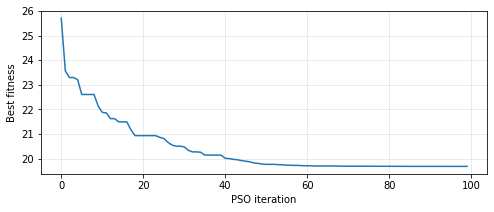

In [8]:
sample_time = 0.05
plant_integrator = "rk4"  # matches the hardware model's RK4 prediction; "euler" is the old forward step



curr_state = np.array([7.0, 10.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0])

curr_control = np.zeros(4)

xref = reference_horizon(0.0, horizon=25, sample_time=sample_time)

last_best = np.zeros((25, 4))



config_contract = pd.Series({

    "Ts": sample_time, "Nx": 12, "n_U": 4, "Nu": 25,

    "particles": 10, "iterations": 100, "u_min": -100,

    "u_max": 100, "du_max": 20, "Q": [1, 1, 1, 3, 3, 3] + [0] * 6,

    "Qf": [10, 10, 10, 30, 30, 30] + [0] * 6,

    "R": [0.0005] * 4,

})

display(config_contract)



one_step_result = None

predicted_next_state = None

if solver is not None:

    try:

        one_step_result = solver.solve(

            curr_state, xref, curr_control, last_best, timeout_seconds=120.0

        )

        best_controls = one_step_result.control_sequence

        fitness = one_step_result.best_fitness

        finite = np.all(np.isfinite(best_controls))

        absolute_ok = np.all(np.abs(best_controls) <= 100.0 + 1e-3)

        deltas = np.diff(np.vstack([curr_control, best_controls]), axis=0)

        delta_ok = np.all(np.abs(deltas) <= 20.0 + 1e-3)

        fitness_has_signal = bool(np.any(np.abs(fitness) >= 1.0 / 32768.0))

        predicted_next_state = quadrotor_step(curr_state, best_controls[0], sample_time, method=plant_integrator)

        print({

            "iterations": one_step_result.iterations,

            "latency_seconds": one_step_result.elapsed_seconds,

            "first_control": best_controls[0].tolist(),

            "fitness_min": float(np.min(fitness)),

            "fitness_max": float(np.max(fitness)),

            "fitness_has_signal": fitness_has_signal,

            "finite": bool(finite),

            "absolute_limits_ok": bool(absolute_ok),

            "delta_limits_ok": bool(delta_ok),

            "runtime_status": solver.runtime_status(),

            "pl_output": "25x4 best control sequence",

            "predicted_next_state_ps": predicted_next_state.tolist(),

        })

        if one_step_result.iterations != 100 or not fitness_has_signal:

            print("Diagnostic: expected 100 completed iterations and a nonzero fitness signal for this nonzero reference. Verify that the board overlay manifest is revision 4 and was packaged from the timing-clean nmpc_solver_v2 XSA.")



        plt.figure(figsize=(8, 3))

        plt.plot(fitness)

        plt.xlabel("PSO iteration")

        plt.ylabel("Best fitness")

        plt.grid(True, alpha=0.3)

        plt.show()

    except TimeoutError as error:

        print("Solver timeout:", error)

        print("Runtime status:", solver.runtime_status())

else:

    print("One-step hardware solve skipped.")


## 17. Run a Closed-Loop Quadrotor Hardware Test

The bounded loop sends state to PL, waits for the optimized trajectory, applies its first control to the software plant, shifts the trajectory for warm start, and advances the spiral reference. It records state, control, fitness, latency, timeout, and constraint status. `latency_seconds` covers `ap_start` to `ap_done`; `ps_overhead_seconds` is the rest of each `solve()` call (input encoding, cache flush and invalidate, launch, polling exit, output decoding), which a real-time control period must also include.

`closed_loop_steps` sets the run length (10 is the smoke test; 100 steps take about 52 s of board time) and `closed_loop_trials` repeats the run from the same initial state and zero warm start (5 x 100 steps take about 4.4 min). The free-running hardware RNG is not reset, so the trials share one continuing random stream and sample the PSO's run-to-run spread. The software plant uses the same equations as the hardware prediction model: this is a perfect-model, offline HIL test, not real-time control (one solve takes about 0.52 s against Ts = 0.05 s).


trial 0: 10 steps, RMSE 0.229 m, peak tilt 0.060 rad


,steps_completed,timeouts,delta_violations,absolute_violations,steps_at_du_max,plant_limit_ok,position_rmse_m,position_max_error_m,peak_roll_pitch_rad,max_control_step,latency_mean_s,latency_max_s,ps_overhead_median_s,ps_overhead_max_s
trial,,,,,,,,,,,,,,
0,10,0,0,0,0,True,0.229133,0.380632,0.060167,17.742615,0.522983,0.523237,0.001569,0.001917


,position_rmse_m,position_max_error_m,peak_roll_pitch_rad,max_control_step,latency_mean_s,latency_max_s,ps_overhead_median_s,ps_overhead_max_s
mean,0.229133,0.380632,0.060167,17.742615,0.522983,0.523237,0.001569,0.001917
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.229133,0.380632,0.060167,17.742615,0.522983,0.523237,0.001569,0.001917
max,0.229133,0.380632,0.060167,17.742615,0.522983,0.523237,0.001569,0.001917


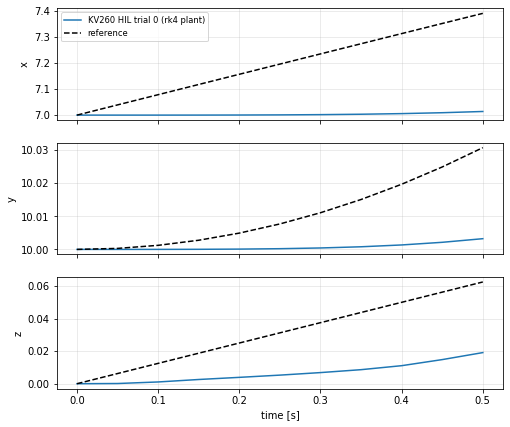

In [9]:
closed_loop_steps = 10  # 10 = smoke test; about 0.52 s of board time per step (100 steps take about 52 s)
closed_loop_trials = 1  # repeats from the same initial state and zero warm start (5 x 100 steps take about 4.4 min)


def run_closed_loop(trial):
    rows, states, controls = [], [], []
    state = curr_state.copy()
    control = curr_control.copy()
    warm_start = last_best.copy()
    timed_out = False
    for step in range(closed_loop_steps):
        current_time = step * sample_time
        step_reference = reference_horizon(current_time, 25, sample_time)
        try:
            call_started = time.monotonic()
            result = solver.solve(state, step_reference, control, warm_start, 120.0)
            solve_call = time.monotonic() - call_started
            sequence = result.control_sequence
            applied_control = sequence[0].copy()
            delta_violation = bool(np.any(np.abs(applied_control - control) > 20.0 + 1e-3))
            absolute_violation = bool(np.any(np.abs(applied_control) > 100.0 + 1e-3))
            next_state = quadrotor_step(state, applied_control, sample_time, method=plant_integrator)
            warm_start = np.vstack([sequence[1:], sequence[-1]])
            fitness = float(result.best_fitness[-1])
            latency = result.elapsed_seconds
        except TimeoutError:
            timed_out = True
            applied_control = np.full(4, np.nan)
            next_state = state.copy()
            delta_violation = absolute_violation = False
            fitness = latency = solve_call = np.nan
        rows.append({
            "trial": trial, "step": step, "time": current_time, "fitness": fitness,
            "latency_seconds": latency, "timeout": timed_out,
            # Whole solve() call; the overhead is the PS-side part outside ap_start..ap_done
            # (input encoding, cache flush/invalidate, launch, polling exit, output decoding).
            "solve_call_seconds": solve_call, "ps_overhead_seconds": solve_call - latency,
            "delta_violation": delta_violation,
            "absolute_violation": absolute_violation,
        })
        states.append(state.copy())
        controls.append(applied_control.copy())
        if timed_out:
            break
        state, control = next_state, applied_control
    if not timed_out:
        states.append(state.copy())  # plant state after the last applied control
    table = pd.DataFrame(rows)
    states = np.asarray(states)
    controls = np.asarray(controls)
    metrics = {
        "trial": trial,
        "steps_completed": int((~table["timeout"]).sum()),
        "timeouts": int(table["timeout"].sum()),
        "delta_violations": int(table["delta_violation"].sum()),
        "absolute_violations": int(table["absolute_violation"].sum()),
        "latency_mean_s": float(table["latency_seconds"].mean()),
        "latency_min_s": float(table["latency_seconds"].min()),
        "latency_max_s": float(table["latency_seconds"].max()),
        "ps_overhead_median_s": float(table["ps_overhead_seconds"].median()),
        "ps_overhead_max_s": float(table["ps_overhead_seconds"].max()),
        **tracking_metrics(states, controls, curr_control, sample_time),
    }
    return {"table": table, "states": states, "controls": controls, "metrics": metrics}


closed_loop_runs = []
if solver is not None:
    for trial in range(closed_loop_trials):
        closed_loop_runs.append(run_closed_loop(trial))
        trial_result = closed_loop_runs[-1]["metrics"]
        print(f"trial {trial}: {trial_result['steps_completed']} steps, "
              f"RMSE {trial_result['position_rmse_m']:.3f} m, peak tilt {trial_result['peak_roll_pitch_rad']:.3f} rad")

closed_loop_metrics = {}
if closed_loop_runs:
    closed_loop_table = pd.concat([run["table"] for run in closed_loop_runs], ignore_index=True)
    trial_metrics = pd.DataFrame([run["metrics"] for run in closed_loop_runs]).set_index("trial")
    key_metrics = ["position_rmse_m", "position_max_error_m", "peak_roll_pitch_rad", "max_control_step",
                   "latency_mean_s", "latency_max_s", "ps_overhead_median_s", "ps_overhead_max_s"]
    display(trial_metrics[["steps_completed", "timeouts", "delta_violations", "absolute_violations",
                           "steps_at_du_max", "plant_limit_ok", *key_metrics]])
    across_trials = trial_metrics[key_metrics].agg(["mean", "std", "min", "max"])
    display(across_trials)
    latencies = closed_loop_table["latency_seconds"].dropna()
    overheads = closed_loop_table["ps_overhead_seconds"].dropna()
    closed_loop_metrics = {
        "plant_integrator": plant_integrator,
        "steps_requested": closed_loop_steps,
        "trials": closed_loop_trials,
        "timeouts": int(trial_metrics["timeouts"].sum()),
        "plant_limit_ok": bool(trial_metrics["plant_limit_ok"].all()),
        "control_bounds_ok": bool((trial_metrics["absolute_violations"] == 0).all()),
        "delta_violations": int(trial_metrics["delta_violations"].sum()),
        "latency_s": {
            "solves": int(latencies.size), "min": float(latencies.min()), "median": float(latencies.median()),
            "p95": float(latencies.quantile(0.95)), "max": float(latencies.max()),
        },
        "ps_overhead_s": {
            "solves": int(overheads.size), "min": float(overheads.min()), "median": float(overheads.median()),
            "p95": float(overheads.quantile(0.95)), "max": float(overheads.max()),
        },
        "across_trials": across_trials.to_dict(),
        "per_trial": [run["metrics"] for run in closed_loop_runs],
    }
    reference_history = spiral_reference(np.arange(max(len(run["states"]) for run in closed_loop_runs)) * sample_time)
    times = np.arange(len(reference_history)) * sample_time
    fig, axes = plt.subplots(3, 1, figsize=(8, 7), sharex=True)
    for axis, index, label in zip(axes, range(3), ("x", "y", "z")):
        for run in closed_loop_runs:
            axis.plot(times[:len(run["states"])], run["states"][:, index],
                      label=f"KV260 HIL trial {run['metrics']['trial']} ({plant_integrator} plant)")
        axis.plot(times, reference_history[:, index], "k--", label="reference")
        axis.set_ylabel(label)
        axis.grid(True, alpha=0.3)
    axes[0].legend(fontsize="small")
    axes[-1].set_xlabel("time [s]")
    plt.show()
else:
    closed_loop_table = pd.DataFrame()
    reference_history = np.empty((0, 12))
    print("Closed-loop hardware test skipped.")


## 18. Compare Hardware Results with the MATLAB NMPC Model

A descriptive comparison, not an apples-to-apples benchmark. `drone_spiral_dir.mat` holds the MATLAB `QuadrotorNMPC.m` run on the same spiral reference and initial state; both are scored with `tracking_metrics` over the same samples. The setups differ: MATLAB uses `fmincon`, a 60-step horizon, weight 1 on position and attitude errors, `0.02 u^2`, no terminal cost, no `du` bound, and a forward-Euler plant. The HLS PSO uses 25 steps, `Q`/`Qf`/`R` from `config.hpp`, `du_max = 20`, Q17.15 top arithmetic, and a half-precision model. Both use normalized controls in [-100, 100].



## 19. Diagnose Timeouts, AXI Errors, and Invalid Results



The diagnostic cell checks stale address metadata, mismatched artifacts, invalid DMA addresses, cache handling assumptions, worker handshake topology, random-stream topology, reset status, and GPIO slicing.

In [ ]:
matlab_file = repo_root / "app/matlab_ws/drone_spiral_dir.mat"
matlab_comparison = {
    "available": False,
    "file": str(matlab_file),
    "notes": [
        "Descriptive comparison, not an apples-to-apples benchmark.",
        "Optimizer: MATLAB fmincon (QuadrotorNMPC.m) vs HLS PSO, 10 particles x 100 iterations.",
        "Horizon: MATLAB round(3/0.05) = 60 steps vs 25 steps (SNIFFBOT_CONFIG).",
        "Weights: MATLAB weight 1 on x,y,z,phi,theta,psi errors, 0.02 u^2, no terminal cost, no du bound; "
        "HLS Q=[1,1,1,3,3,3], Qf=[10,10,10,30,30,30], R=0.0005, du_max=20.",
        f"Plant: MATLAB QuadrotorSystem.m uses forward Euler; this run uses the {plant_integrator} plant.",
        "Arithmetic: HLS top values are Q17.15 and the model type is half precision.",
        "Alignment: row k is the state at t = k*Ts (Ts = 0.05 s); row 0 is the shared initial state, the last "
        "row the state after the last applied control. Both use normalized controls in [-100, 100].",
        "Control steps start from u = 0 for both (MATLAB's initial guess; MATLAB has no du bound, so "
        "steps_at_du_max is informational for it).",
    ],
}
if closed_loop_runs and matlab_file.is_file():
    try:
        from scipy.io import loadmat
    except ImportError:
        matlab_comparison["notes"].append("SciPy is unavailable; MAT comparison skipped.")
    else:
        data = loadmat(matlab_file)
        samples = min(max(len(run["states"]) for run in closed_loop_runs), len(data["xHistory"]))
        matlab_states = np.asarray(data["xHistory"][:samples, :12], dtype=float)
        matlab_controls = np.asarray(data["uHistory"][:samples - 1, :4], dtype=float)
        matlab_reference = np.asarray(data["xRef_out"][:samples, 0:3], dtype=float)
        per_trial = []
        for run in closed_loop_runs:
            count = min(samples, len(run["states"]))
            controls = run["controls"][:count - 1]
            valid = np.all(np.isfinite(controls), axis=1)
            per_trial.append({
                "trial": run["metrics"]["trial"],
                "samples": count,
                "state_rmse_vs_matlab": float(np.sqrt(np.mean((run["states"][:count] - matlab_states[:count]) ** 2))),
                "control_rmse_vs_matlab": float(np.sqrt(np.mean((controls[valid] - matlab_controls[:count - 1][valid]) ** 2))),
            })
        matlab_comparison.update({
            "available": True,
            "samples": samples,
            "reference_max_deviation_m": float(np.abs(
                matlab_reference - spiral_reference(np.arange(samples) * sample_time)[:, 0:3]
            ).max()),
            "matlab_metrics": tracking_metrics(matlab_states, matlab_controls, np.zeros(4), sample_time),
            "per_trial": per_trial,
        })
        shown = ["samples", "position_rmse_m", "position_max_error_m", "position_max_error_time_s",
                 "final_position_error_m", "peak_roll_pitch_rad", "max_abs_control", "max_control_step",
                 "steps_at_du_max"]
        side_by_side = pd.DataFrame({
            "MATLAB fmincon": {key: matlab_comparison["matlab_metrics"][key] for key in shown},
            **{f"KV260 trial {run['metrics']['trial']}": {key: run["metrics"][key] for key in shown}
               for run in closed_loop_runs},
        })
        display(side_by_side)
        display(pd.DataFrame(per_trial).set_index("trial"))
print("\n".join(matlab_comparison["notes"]))
print({key: matlab_comparison.get(key) for key in ("available", "file", "samples", "reference_max_deviation_m")})


def diagnose_platform():
    recommendations = []
    if not paths["handoff_hwh"].is_file() or not paths["handoff_bda"].is_file():
        recommendations.append("Copy the matching design_nmpc_solver HWH and BDA from nmpc_solver.xsa_FILES.")
    if not hardware_map_checks.get("pso_fsm_control_interfaces", False):
        recommendations.append("Regenerate the platform; pso_fsm_0 must expose both AXI-Lite interfaces.")
    if not hardware_map_checks.get("worker_done_wiring", False):
        recommendations.append("Regenerate the platform with all worker ap_done ports connected to the FSM.")
    if not artifacts_ready:
        recommendations.append("Package a matching nmpc_solver.bit, nmpc_solver.hwh, and manifest.json set.")
    if not all(layout_table["fits"]) or any(layout_table["overlaps"] != ""):
        recommendations.append("Correct direct pointer constants and BRAM ranges before synthesis.")

    runtime = {"exported_ps_map": exported_ps_map.to_dict(orient="records")}
    if solver is not None:
        runtime["ap_ctrl"] = f"0x{solver.control.read(0x00):08x}"
        runtime["ap_return"] = solver.control.read(0x10)
        runtime["register_map"] = solver.register_map
    return {"runtime": runtime, "recommendations": recommendations}


diagnostics = diagnose_platform()
print(json.dumps(diagnostics, indent=2))

## 20. Export Deployment Logs and Validation Results



Save platform tables, address comparisons, runtime metadata, controls, predicted states, histories, timing, diagnostics, and a machine-readable pass/fail report under `validation_logs/<run_id>/`, one directory per run (`<UTC time>_<plant>_<steps>x<trials>`), so earlier runs are never overwritten. Each check is reported as `pass`, `fail`, or `skipped` with a reason; a skipped check could not run (for example, the repository Tcl is not on the board) and is not a failure.

In [ ]:
run_id = time.strftime("%Y%m%dT%H%M%SZ", time.gmtime()) + f"_{plant_integrator}_{closed_loop_steps}x{closed_loop_trials}"
run_dir = paths["logs"] / run_id
run_dir.mkdir(parents=True, exist_ok=True)
path_status.to_csv(run_dir / "path_status.csv", index=False)
component_table.to_csv(run_dir / "hls_components.csv", index=False)
csv_addresses.to_csv(run_dir / "address_segments_checked_in.csv", index=False)
exported_ps_map.to_csv(run_dir / "exported_ps_register_map.csv", index=False)
layout_table.to_csv(run_dir / "bram_layout.csv", index=False)
closed_loop_table.to_csv(run_dir / "solver_timing.csv", index=False)
if closed_loop_runs:
    pd.DataFrame(closed_loop_metrics["per_trial"]).to_csv(run_dir / "closed_loop_trials.csv", index=False)
    histories = {"reference": reference_history}
    for run in closed_loop_runs:
        histories[f"states_trial{run['metrics']['trial']}"] = run["states"]
        histories[f"controls_trial{run['metrics']['trial']}"] = run["controls"]
    np.savez(run_dir / "closed_loop_histories.npz", **histories)
if one_step_result is not None:
    np.save(run_dir / "best_control_sequence.npy", one_step_result.control_sequence)
    np.save(run_dir / "best_fitness.npy", one_step_result.best_fitness)
if predicted_next_state is not None:
    np.save(run_dir / "predicted_next_state.npy", predicted_next_state)

run_config = {
    "run_id": run_id,
    "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()),
    "overlay": {
        "path": str(paths["overlay"]),
        "source_xsa": manifest.get("source_xsa") if manifest else None,
        "files": manifest.get("files") if manifest else None,
    },
    "solver_config": config_contract.to_dict(),
    "plant_integrator": plant_integrator,
    "closed_loop_steps": closed_loop_steps,
    "closed_loop_trials": closed_loop_trials,
    "initial_state": curr_state.tolist(),
    "initial_control": curr_control.tolist(),
    "warm_start": "zeros (25 x 4) at the start of each trial, then the shifted previous solution",
    "reference": "quadrotor.spiral_reference (the Quadrotor_xref.m spiral), sampled at t = k * Ts",
    "rng": "free-running hardware stream, not reset between solves or trials",
}


def tri_state(*checks):
    """True/False, or None (skipped) when an input check could not run."""
    if any(check is None for check in checks):
        return None
    return bool(all(checks))


tcl_skip_reason = "repository Vivado Tcl not present on this copy; static Tcl audit not run"
overlay_skip_reason = "overlay not loaded (PYNQ or matching artifacts unavailable)"
skip_reasons = {
    "solver_completion": overlay_skip_reason,
    "numerical_validity": overlay_skip_reason,
    "control_constraints": overlay_skip_reason,
    "kv260_compatibility": tcl_skip_reason,
    "clock_reset": tcl_skip_reason,
    "closed_loop_no_timeouts": "closed loop not run",
    "closed_loop_plant_limit": "closed loop not run",
    "closed_loop_control_constraints": "closed loop not run",
}
validation_report = {
    "kv260_compatibility": tri_state(clock_checks.get("part_ok"), clock_checks.get("board_ok")),
    "clock_reset": tri_state(clock_checks.get("clock_matches_hls"), clock_checks.get("synchronized_reset")),
    "exported_pso_fsm_register_map": bool(hardware_map_checks.get("pso_fsm_control_interfaces")),
    "exported_control_base": bool(hardware_map_checks.get("control_base")),
    "exported_argument_base": bool(hardware_map_checks.get("argument_base")),
    "worker_done_wiring": bool(hardware_map_checks.get("worker_done_wiring")),
    "bram_layout": bool(all(layout_table["fits"]) and all(layout_table["overlaps"] == "")),
    "overlay_artifacts": bool(artifacts_ready),
    # The single solve is skipped without a loaded overlay; a solve that runs and fails is a failure.
    "solver_completion": one_step_result is not None if solver is not None else None,
    "numerical_validity": bool(
        one_step_result is not None and np.all(np.isfinite(one_step_result.control_sequence))
    ) if solver is not None else None,
    "control_constraints": bool(
        one_step_result is not None
        and np.all(np.abs(one_step_result.control_sequence) <= 100.0 + 1e-3)
    ) if solver is not None else None,
    "closed_loop_no_timeouts": closed_loop_metrics["timeouts"] == 0 if closed_loop_metrics else None,
    "closed_loop_plant_limit": closed_loop_metrics.get("plant_limit_ok"),
    "closed_loop_control_constraints": tri_state(
        closed_loop_metrics.get("control_bounds_ok"),
        closed_loop_metrics["delta_violations"] == 0 if closed_loop_metrics else None,
    ),
}
validation_status = {
    name: "skipped" if value is None else "pass" if value else "fail" for name, value in validation_report.items()
}
skipped_checks = {name: skip_reasons.get(name, "input unavailable")
                  for name, value in validation_report.items() if value is None}
export_payload = {
    "run_config": run_config,
    "validation": validation_status,
    "skipped_checks": skipped_checks,
    "project": project_config,
    "clock_checks": clock_checks,
    "hardware_map_checks": hardware_map_checks,
    "closed_loop_metrics": closed_loop_metrics,
    "artifact_checks": artifact_checks,
    "matlab_comparison": matlab_comparison,
    "diagnostics": diagnostics,
}
(run_dir / "validation_report.json").write_text(
    json.dumps(export_payload, indent=2, default=str) + "\n", encoding="utf-8"
)
display(pd.Series(validation_status, name="status"))
if skipped_checks:
    print("Skipped (not failed):", skipped_checks)
print("Validation logs written to", run_dir)
if solver is not None:
    solver.close()